# IMPORTING LIBRARIES

In [1]:
import pandas as pd                      
import numpy as np                       
import matplotlib.pyplot as plt          
import seaborn as sns                    
from scipy import stats                                                                  # classical tests (t-test, chi-square, etc.)
import statsmodels.api as sm                                                             # regression and diagnostics
import statsmodels.formula.api as smf                                                    # R-style formula regression
from statsmodels.stats.multicomp import pairwise_tukeyhsd                                # post-hoc test after ANOVA
from statsmodels.stats.outliers_influence import variance_inflation_factor               # multicollinearity check
from statsmodels.stats.diagnostic import het_breuschpagan                                # heteroscedasticity test

In [2]:
sns.set_theme(style="whitegrid")         # clean plot style
ALPHA = 0.05 

# LOAD THE DATA

In [3]:
df = pd.read_csv('insurance.csv')

In [4]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [5]:
(df.shape)                                    # No of Rows & Columns 

(1338, 7)

In [6]:
df.head()                                    # First 5 Rows 

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
df.info()                             # Display information about columns, data types and non-null values

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [9]:
df.describe()                              # Generate statistical summary of numerical columns

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [11]:
print(df.isnull().sum())                              # Count missing values in every column        

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


# DISTRIBUTION OF THE TARGET VARIABLE 

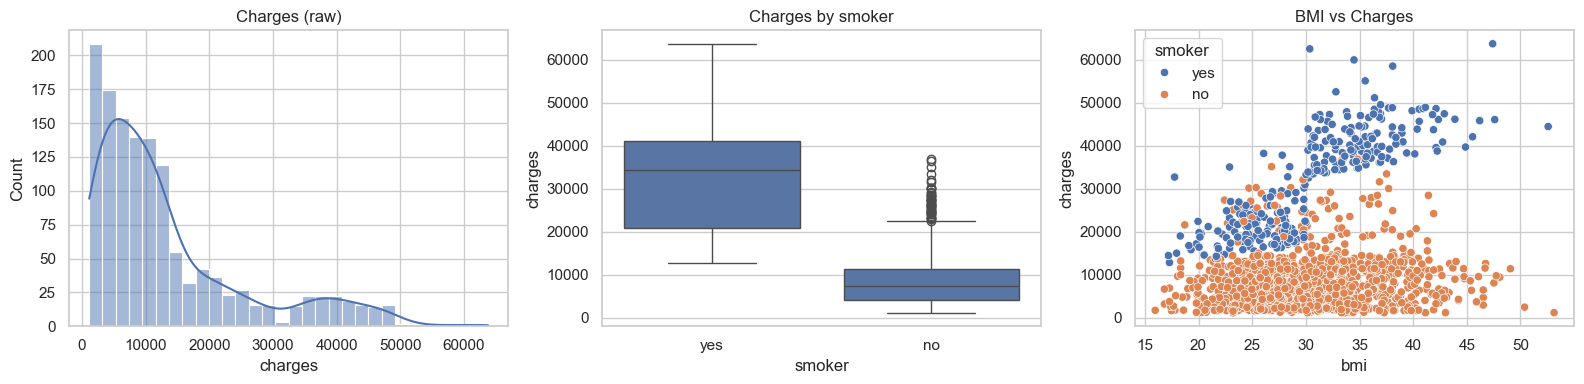

('Skewness of charges:', np.float64(1.5158796580240388))

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['charges'], kde=True, ax=ax[0])                            # raw charges
ax[0].set_title('Charges (raw)')

sns.boxplot(x='smoker', y='charges', data=df, ax=ax[1])                    # charges by smoking status
ax[1].set_title('Charges by smoker')

sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, ax=ax[2])     # BMI vs charges
ax[2].set_title('BMI vs Charges')
plt.tight_layout(); plt.show()

("Skewness of charges:", df['charges'].skew())                             # > 1 means strongly right-skewed

# WELCH'S TEST ( SMOKER VS NON-SMOKER)

Shapiro smokers    : ShapiroResult(statistic=np.float64(0.9395519386965634), pvalue=np.float64(3.6249900590074277e-09))
Shapiro non-smokers: ShapiroResult(statistic=np.float64(0.8728637657160003), pvalue=np.float64(1.4459006706130622e-28))


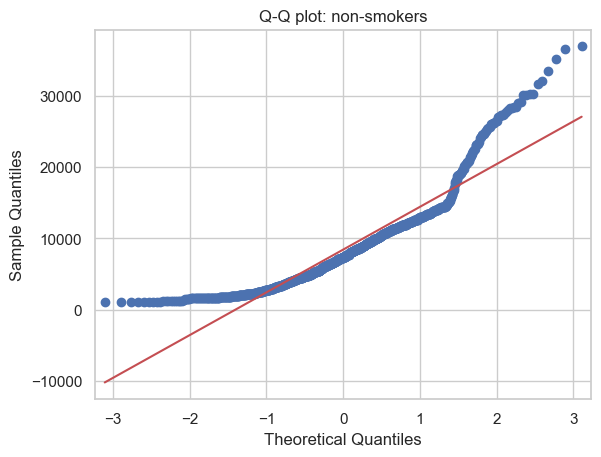

Levene: LeveneResult(statistic=np.float64(332.6135162726081), pvalue=np.float64(1.5593284881803726e-66))
t = 32.752, p = 5.889e-103
Mean diff = 23615.96, 95% CI = (22197.21, 25034.71)
Cohen's d = 3.16
Mann-Whitney U: MannwhitneyuResult(statistic=np.float64(284133.0), pvalue=np.float64(5.270233444503571e-130))


In [16]:
smoker = df.loc[df['smoker'] == 'yes', 'charges']           # charges of smokers
nonsmk = df.loc[df['smoker'] == 'no',  'charges']           # charges of non-smokers

# Assumption 1: normality (Shapiro-Wilk) H0 = data is normal 

print("Shapiro smokers    :", stats.shapiro(smoker))
print("Shapiro non-smokers:", stats.shapiro(nonsmk))

# With n this large, Shapiro often rejects for tiny deviations, so also inspect a Q-Q plot.
sm.qqplot(nonsmk, line='s'); plt.title("Q-Q plot: non-smokers"); plt.show()

# Assumption 2: equal variances (Levene). H0 = variances equal.
print("Levene:", stats.levene(smoker, nonsmk))

# Main test: Welch's t-test (does NOT assume equal variances) 
t_stat, p_val = stats.ttest_ind(smoker, nonsmk, equal_var=False)
print(f"t = {t_stat:.3f}, p = {p_val:.3e}")

# 95% confidence interval for the difference in means (Welch)
n1, n2 = len(smoker), len(nonsmk)
v1, v2 = smoker.var(ddof=1), nonsmk.var(ddof=1)
diff = smoker.mean() - nonsmk.mean()                                          # observed mean difference
se = np.sqrt(v1/n1 + v2/n2)                                                   # standard error of the difference
dof = (v1/n1 + v2/n2)**2 / ((v1/n1)**2/(n1-1) + (v2/n2)**2/(n2-1))            # Welch-Satterthwaite df
ci = (diff - stats.t.ppf(0.975, dof)*se, diff + stats.t.ppf(0.975, dof)*se)
print(f"Mean diff = {diff:.2f}, 95% CI = ({ci[0]:.2f}, {ci[1]:.2f})")

# Effect size: Cohen's d (using pooled SD) 
pooled_sd = np.sqrt(((n1-1)*v1 + (n2-1)*v2) / (n1+n2-2))
print(f"Cohen's d = {diff/pooled_sd:.2f}")                      # 0.2 small, 0.5 medium, 0.8 large

# Robustness check: non-parametric alternative (no normality needed) 
print("Mann-Whitney U:", stats.mannwhitneyu(smoker, nonsmk, alternative='two-sided'))

# CHI-SQUARE TEST OF INDEPENDENCE (SMOKER VS SEX)

In [18]:
# Contingency table of observed counts

ct = pd.crosstab(df['sex'], df['smoker'])
print(ct)

chi2, p, dof, expected = stats.chi2_contingency(ct)         # returns statistic, p-value, df, expected counts
print(f"chi2 = {chi2:.3f}, df = {dof}, p = {p:.4f}")

# Assumption: all expected counts should be >= 5
print("Expected counts:\n", pd.DataFrame(expected, index=ct.index, columns=ct.columns))

# Effect size: Cramér's V (0.1 small, 0.3 medium, 0.5 large)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print(f"Cramér's V = {cramers_v:.3f}")

smoker   no  yes
sex             
female  547  115
male    517  159
chi2 = 7.393, df = 1, p = 0.0065
Expected counts:
 smoker          no         yes
sex                           
female  526.433483  135.566517
male    537.566517  138.433483
Cramér's V = 0.074


# CORRELATION ANALYSIS (BMI VS CHARGES , ALSO AGE VS CHARGES )

BMI vs charges: Pearson r=0.198 (p=2.46e-13, 95% CI 0.146 to 0.249); Spearman rho=0.119 (p=1.19e-05)
Age vs charges: Pearson r=0.299 (p=4.89e-29, 95% CI 0.249 to 0.347); Spearman rho=0.534 (p=1.13e-99)


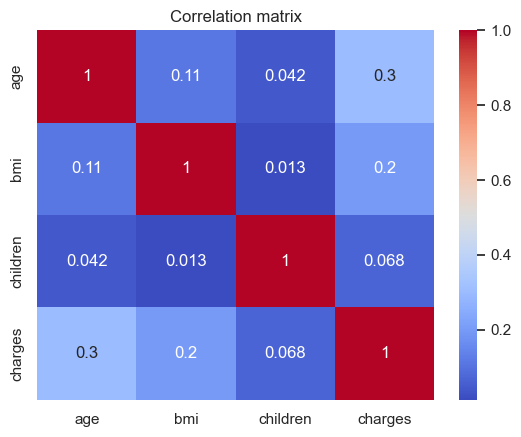

In [21]:
def corr_report(x, y, name):
    """Pearson and Spearman correlation with a 95% CI for Pearson r (Fisher z)."""
    r, p = stats.pearsonr(x, y)                           # linear relationship
    rho, p_s = stats.spearmanr(x, y)                      # monotonic, rank-based (robust to skew)
    z = np.arctanh(r); se = 1/np.sqrt(len(x)-3)           # Fisher z-transform for the CI
    lo, hi = np.tanh(z - 1.96*se), np.tanh(z + 1.96*se)
    print(f"{name}: Pearson r={r:.3f} (p={p:.2e}, 95% CI {lo:.3f} to {hi:.3f}); "
          f"Spearman rho={rho:.3f} (p={p_s:.2e})")

corr_report(df['bmi'], df['charges'], "BMI vs charges")
corr_report(df['age'], df['charges'], "Age vs charges")

# Heatmap of all numeric correlations for the report
sns.heatmap(df[['age','bmi','children','charges']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation matrix"); plt.show()

# ONE - WAY ANNOVA ( CHARGES ACROSS REGIONS )

In [23]:
groups = [g['charges'].values for _, g in df.groupby('region')]      # one array per region

# Assumption: homogeneity of variances
print("Levene:", stats.levene(*groups))

# Main test
F, p = stats.f_oneway(*groups)
print(f"F = {F:.3f}, p = {p:.4f}")

# Effect size: eta-squared = SS_between / SS_total
grand = df['charges'].mean()
ss_between = sum(len(g)*(g.mean()-grand)**2 for g in groups)
ss_total = ((df['charges'] - grand)**2).sum()
print(f"eta-squared = {ss_between/ss_total:.4f}")

# Non-parametric backup (use if normality/variance assumptions fail)
print("Kruskal-Wallis:", stats.kruskal(*groups))

# Post-hoc: only meaningful if ANOVA is significant
print(pairwise_tukeyhsd(df['charges'], df['region'], alpha=ALPHA))

Levene: LeveneResult(statistic=np.float64(5.559966758410606), pvalue=np.float64(0.0008610590250786703))
F = 2.970, p = 0.0309
eta-squared = 0.0066
Kruskal-Wallis: KruskalResult(statistic=np.float64(4.734181215658743), pvalue=np.float64(0.19232908072121002))
       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
  group1    group2   meandiff  p-adj    lower      upper   reject
-----------------------------------------------------------------
northeast northwest  -988.8091 0.7245 -3428.9343 1451.3161  False
northeast southeast  1329.0269 0.4745 -1044.9417 3702.9955  False
northeast southwest -1059.4471 0.6792 -3499.5723 1380.6781  False
northwest southeast  2317.8361 0.0583   -54.1994 4689.8716  False
northwest southwest    -70.638 0.9999 -2508.8826 2367.6066  False
southeast southwest -2388.4741 0.0477 -4760.5096  -16.4386   True
-----------------------------------------------------------------


# MULTIPLE LINEAR REGRESSION 

                            OLS Regression Results                            
Dep. Variable:        np.log(charges)   R-squared:                       0.768
Model:                            OLS   Adj. R-squared:                  0.767
Method:                 Least Squares   F-statistic:                     549.8
Date:                Sat, 10 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:51:29   Log-Likelihood:                -808.52
No. Observations:                1338   AIC:                             1635.
Df Residuals:                    1329   BIC:                             1682.
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  7

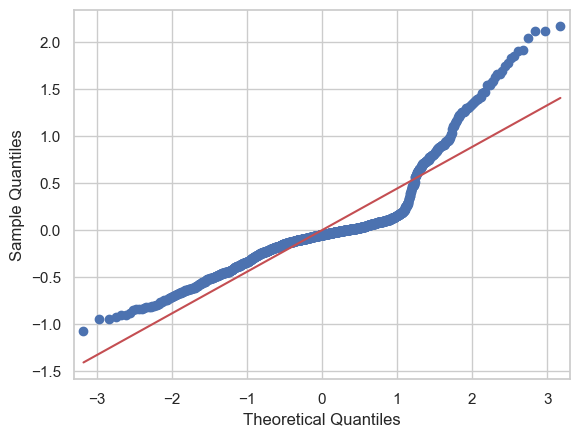

Breusch-Pagan p = 0.0000


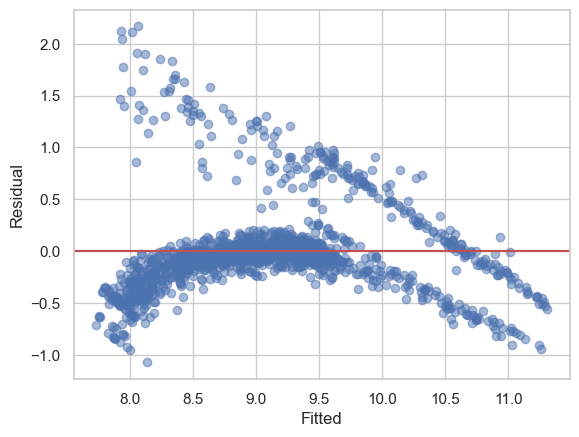

In [24]:
# Fit OLS using a formula; C() tells statsmodels to dummy-code categorical variables

model = smf.ols("np.log(charges) ~ age + bmi + children + C(smoker) + C(sex) + C(region)",
                data=df).fit()
print(model.summary())          # coefficients, p-values, R², F-test, etc.
print(model.conf_int())         # 95% confidence intervals for each coefficient

#  Assumption checks 
# 1) Multicollinearity: VIF > 5 (or 10) is a concern
X = sm.add_constant(pd.get_dummies(df[['age','bmi','children','smoker','sex','region']],
                                   drop_first=True).astype(float))
vif = pd.DataFrame({'feature': X.columns,
                    'VIF': [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]})
print(vif)

# 2) Residual normality
print("Shapiro on residuals:", stats.shapiro(model.resid))
sm.qqplot(model.resid, line='s'); plt.show()

# 3) Constant variance (Breusch-Pagan; H0 = homoscedastic)
bp = het_breuschpagan(model.resid, model.model.exog)
print(f"Breusch-Pagan p = {bp[1]:.4f}")

# 4) Residuals vs fitted: should look like a random cloud
plt.scatter(model.fittedvalues, model.resid, alpha=.5)
plt.axhline(0, color='r'); plt.xlabel("Fitted"); plt.ylabel("Residual"); plt.show()